# Quantum Generative Adversarial Network (qGAN) for S&P 500 Return Synthesis

This notebook builds the final quantum version of the earlier classical project.

**Pipeline:** S&P 500 prices → daily log returns → 8 bins → 3-qubit parameterized quantum generator → classical PyTorch discriminator → synthetic return samples → synthetic price paths → KS/ACF/VaR/CVaR validation.

A 3-qubit generator is natural because $2^3=8$ basis states. Each computational-basis state is mapped to one return bin.


In [1]:
%pip install qiskit qiskit-aer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 54.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 83.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 70.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.7 MB/s eta 0:00:00


In [2]:
import sys
import platform
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from scipy.stats import ks_2samp, skew, kurtosis
from statsmodels.tsa.stattools import acf
import yfinance as yf

import qiskit
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector

import qiskit_aer

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

In [3]:
TICKER = "^GSPC"
START_DATE = "2020-01-01"
END_DATE = "2025-01-01"

print("Downloading", TICKER, "...")
raw = yf.download(TICKER, start=START_DATE, end=END_DATE, progress=False, auto_adjust=False)

if isinstance(raw.columns, pd.MultiIndex):
    close = raw["Close"].iloc[:, 0]
else:
    close = raw["Close"]

close = close.dropna()
returns_series = np.log(close / close.shift(1)).dropna()
returns = returns_series.to_numpy(dtype=float)

print("Number of prices:", len(close))
print("Number of daily returns:", len(returns))
print("First date:", close.index[0])
print("Last date:", close.index[-1])
print("Return mean:", returns.mean())
print("Return std:", returns.std())
print("Return min/max:", returns.min(), returns.max())
print("\nFirst 10 returns:")
print(returns[:10])

Number of prices: 1258
Number of daily returns: 1257
First date: 2020-01-02 00:00:00
Last date: 2024-12-31 00:00:00
Return mean: 0.0004699812377682979
Return std: 0.013494295121898904
Return min/max: -0.12765219747281742 0.08968323251796326

First 10 returns:
[-0.00708491  0.00352715 -0.00280718  0.00489047  0.00663321 -0.00285926
  0.00695199 -0.00151568  0.00186845  0.00833175]


In [4]:
NUM_QUBITS = 3
NUM_BINS = 2 ** NUM_QUBITS

low, high = np.percentile(returns, [1, 99])
bin_edges = np.linspace(low, high, NUM_BINS + 1)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

hist, _ = np.histogram(returns, bins=bin_edges)
real_distribution = hist.astype(float)
real_distribution /= real_distribution.sum()

bin_table = pd.DataFrame({
    "bin": np.arange(NUM_BINS),
    "state": [format(i, "03b") for i in range(NUM_BINS)],
    "left": bin_edges[:-1],
    "right": bin_edges[1:],
    "center": bin_centers,
    "count": hist,
    "probability": real_distribution
})

print("=" * 70)
print("8-BIN TARGET DISTRIBUTION")
print("=" * 70)
print("Qubits:", NUM_QUBITS, " | Bins:", NUM_BINS)
print("1st percentile:", low)
print("99th percentile:", high)
print(bin_table.to_string(index=False))
print("Probability sum:", real_distribution.sum())

8-BIN TARGET DISTRIBUTION
Qubits: 3  | Bins: 8
1st percentile: -0.0365904097411609
99th percentile: 0.030280794342777702
 bin state      left     right    center  count  probability
   0   000 -0.036590 -0.028232 -0.032411     20     0.016247
   1   001 -0.028232 -0.019873 -0.024052     25     0.020309
   2   010 -0.019873 -0.011514 -0.015693     90     0.073111
   3   011 -0.011514 -0.003155 -0.007334    244     0.198213
   4   100 -0.003155  0.005204  0.001025    471     0.382616
   5   101  0.005204  0.013563  0.009384    265     0.215272
   6   110  0.013563  0.021922  0.017742     88     0.071487
   7   111  0.021922  0.030281  0.026101     28     0.022746
Probability sum: 1.0


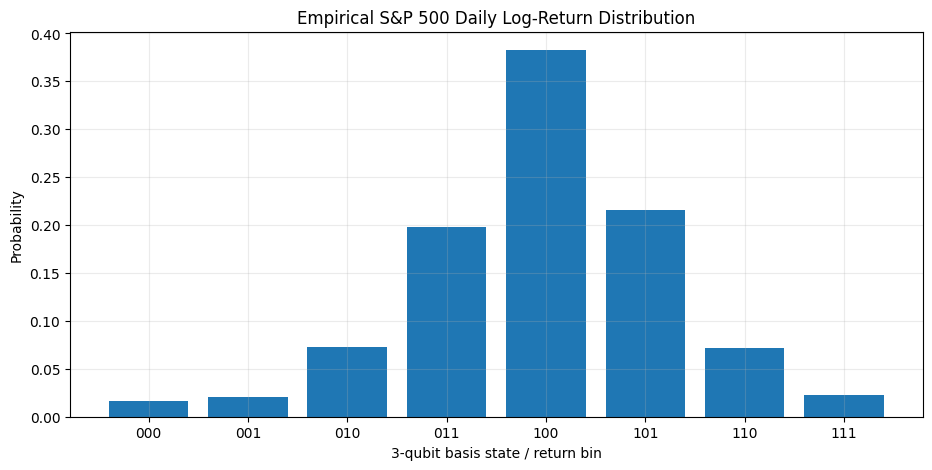

In [5]:
plt.figure(figsize=(11,5))
plt.bar(np.arange(NUM_BINS), real_distribution)
plt.xticks(np.arange(NUM_BINS), [format(i,"03b") for i in range(NUM_BINS)])
plt.xlabel("3-qubit basis state / return bin")
plt.ylabel("Probability")
plt.title("Empirical S&P 500 Daily Log-Return Distribution")
plt.grid(alpha=0.25)
plt.show()

In [6]:
LATENT_DIM = 4

class ClassicalGenerator(nn.Module):
    def __init__(self, latent_dim=4, output_dim=8):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 16),
            nn.ReLU(),
            nn.Linear(16, output_dim),
            nn.Softmax(dim=-1)
        )
    def forward(self, z):
        return self.net(z)

class Discriminator(nn.Module):
    def __init__(self, input_dim=8):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 16),
            nn.LeakyReLU(0.2),
            nn.Linear(16, 1),
            nn.Sigmoid()
        )
    def forward(self, x):
        return self.net(x)

G_classical = ClassicalGenerator(LATENT_DIM, NUM_BINS)
D_classical = Discriminator(NUM_BINS)
criterion = nn.BCELoss()
opt_G = torch.optim.Adam(G_classical.parameters(), lr=0.005)
opt_D = torch.optim.Adam(D_classical.parameters(), lr=0.005)
real_tensor = torch.tensor(real_distribution, dtype=torch.float32).unsqueeze(0)

print("Classical Generator parameters:", sum(p.numel() for p in G_classical.parameters()))
print("Classical Discriminator parameters:", sum(p.numel() for p in D_classical.parameters()))
print(G_classical)
print(D_classical)

Classical Generator parameters: 216
Classical Discriminator parameters: 161
ClassicalGenerator(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): Softmax(dim=-1)
  )
)
Discriminator(
  (net): Sequential(
    (0): Linear(in_features=8, out_features=16, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=16, out_features=1, bias=True)
    (3): Sigmoid()
  )
)


In [7]:
CLASSICAL_EPOCHS = 1000
classical_history = []

for epoch in range(CLASSICAL_EPOCHS):
    # Discriminator
    opt_D.zero_grad()
    real_label = torch.ones(1,1)
    fake_label = torch.zeros(1,1)
    d_real_loss = criterion(D_classical(real_tensor), real_label)
    z = torch.randn(1, LATENT_DIM)
    fake = G_classical(z)
    d_fake_loss = criterion(D_classical(fake.detach()), fake_label)
    d_loss = d_real_loss + d_fake_loss
    d_loss.backward()
    opt_D.step()

    # Generator
    opt_G.zero_grad()
    z = torch.randn(1, LATENT_DIM)
    fake = G_classical(z)
    g_loss = criterion(D_classical(fake), real_label)
    g_loss.backward()
    opt_G.step()

    classical_history.append((epoch+1, d_loss.item(), g_loss.item()))
    if epoch == 0 or (epoch+1) % 100 == 0:
        print(f"Classical epoch {epoch+1:4d}/{CLASSICAL_EPOCHS} | D={d_loss.item():.6f} | G={g_loss.item():.6f}")

G_classical.eval()
with torch.no_grad():
    classical_probs = G_classical(torch.randn(1,LATENT_DIM)).squeeze().numpy()

print("\nReal probabilities:")
print(np.round(real_distribution,6))
print("\nClassical GAN probabilities:")
print(np.round(classical_probs,6))
print("Probability sum:", classical_probs.sum())

Classical epoch    1/1000 | D=1.382341 | G=0.770244
Classical epoch  100/1000 | D=1.334509 | G=0.757156
Classical epoch  200/1000 | D=1.392649 | G=0.706096
Classical epoch  300/1000 | D=1.609577 | G=0.299881
Classical epoch  400/1000 | D=0.823025 | G=1.067329
Classical epoch  500/1000 | D=0.540643 | G=1.528203
Classical epoch  600/1000 | D=1.681726 | G=0.583341
Classical epoch  700/1000 | D=0.801511 | G=0.999424
Classical epoch  800/1000 | D=1.360614 | G=0.639577
Classical epoch  900/1000 | D=1.168437 | G=0.844337
Classical epoch 1000/1000 | D=1.293447 | G=0.774579

Real probabilities:
[0.016247 0.020309 0.073111 0.198213 0.382616 0.215272 0.071487 0.022746]

Classical GAN probabilities:
[0.062002 0.007387 0.017256 0.117913 0.396503 0.257286 0.131542 0.010111]
Probability sum: 1.0


In [8]:
NUM_LAYERS = 2
NUM_PARAMS = NUM_QUBITS * 2 * NUM_LAYERS

def build_generator(num_qubits=3, num_layers=2):
    params = ParameterVector("theta", length=num_qubits*2*num_layers)
    qc = QuantumCircuit(num_qubits)
    k = 0
    for _ in range(num_layers):
        for q in range(num_qubits):
            qc.ry(params[k], q); k += 1
            qc.rz(params[k], q); k += 1
        for q in range(num_qubits-1):
            qc.cx(q, q+1)
    return qc, params

generator_circuit, generator_params = build_generator(NUM_QUBITS, NUM_LAYERS)
print("="*70)
print("QUANTUM GENERATOR")
print("="*70)
print(generator_circuit.draw("text"))
print("Qubits:", NUM_QUBITS)
print("Layers:", NUM_LAYERS)
print("Trainable parameters:", len(generator_params))

QUANTUM GENERATOR
     ┌──────────────┐┌──────────────┐     ┌──────────────┐ ┌──────────────┐»
q_0: ┤ Ry(theta[0]) ├┤ Rz(theta[1]) ├──■──┤ Ry(theta[6]) ├─┤ Rz(theta[7]) ├»
     ├──────────────┤├──────────────┤┌─┴─┐└──────────────┘ ├──────────────┤»
q_1: ┤ Ry(theta[2]) ├┤ Rz(theta[3]) ├┤ X ├───────■─────────┤ Ry(theta[8]) ├»
     ├──────────────┤├──────────────┤└───┘     ┌─┴─┐      ┌┴──────────────┤»
q_2: ┤ Ry(theta[4]) ├┤ Rz(theta[5]) ├──────────┤ X ├──────┤ Ry(theta[10]) ├»
     └──────────────┘└──────────────┘          └───┘      └───────────────┘»
«                                
«q_0: ───────────────────■───────
«      ┌──────────────┐┌─┴─┐     
«q_1: ─┤ Rz(theta[9]) ├┤ X ├──■──
«     ┌┴──────────────┤└───┘┌─┴─┐
«q_2: ┤ Rz(theta[11]) ├─────┤ X ├
«     └───────────────┘     └───┘
Qubits: 3
Layers: 2
Trainable parameters: 12


In [9]:
def quantum_probabilities(theta_values):
    theta_values = np.asarray(theta_values, dtype=float)
    if len(theta_values) != len(generator_params):
        raise ValueError("Wrong number of quantum parameters")
    bound = generator_circuit.assign_parameters(
        dict(zip(generator_params, theta_values)), inplace=False
    )
    state = Statevector.from_instruction(bound)
    probs = np.abs(state.data)**2
    probs = np.real_if_close(probs).astype(float)
    probs = np.maximum(probs, 0)
    return probs / probs.sum()

initial_theta = np.random.uniform(-0.25, 0.25, NUM_PARAMS)
initial_probs = quantum_probabilities(initial_theta)
print("Initial quantum probabilities:")
print(np.round(initial_probs,6))
print("Probability sum:", initial_probs.sum())

Initial quantum probabilities:
[9.41699e-01 1.60000e-05 2.40700e-03 5.60000e-04 4.13060e-02 1.35600e-03
 6.98000e-04 1.19570e-02]
Probability sum: 1.0


In [10]:
SHIFT = np.pi/2

def parameter_shift_jacobian(theta_values):
    theta_values = np.asarray(theta_values, dtype=float)
    J = np.zeros((NUM_BINS, len(theta_values)))
    for j in range(len(theta_values)):
        plus = theta_values.copy(); plus[j] += SHIFT
        minus = theta_values.copy(); minus[j] -= SHIFT
        J[:,j] = 0.5*(quantum_probabilities(plus)-quantum_probabilities(minus))
    return J

J = parameter_shift_jacobian(initial_theta)
print("Jacobian shape:", J.shape)
print("Expected:", (NUM_BINS, NUM_PARAMS))
print("Max |J|:", np.max(np.abs(J)))

Jacobian shape: (8, 12)
Expected: (8, 12)
Max |J|: 0.19670392281511584


# Hybrid qGAN training

The discriminator is classical. The generator parameters are numerical quantum-circuit parameters.

For the generator update:

1. PyTorch calculates $\partial L_G/\partial p$.
2. Parameter shift calculates $\partial p/\partial\theta$.
3. Chain rule gives $\partial L_G/\partial\theta=J^T(\partial L_G/\partial p)$.
4. A small NumPy Adam optimizer updates the PQC parameters.

This is an explicit hybrid quantum-classical training loop.

In [11]:
class NumpyAdam:
    def __init__(self, size, lr=0.03, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr, self.beta1, self.beta2, self.eps = lr, beta1, beta2, eps
        self.m = np.zeros(size); self.v = np.zeros(size); self.t = 0
    def step(self, params, grad):
        self.t += 1
        self.m = self.beta1*self.m + (1-self.beta1)*grad
        self.v = self.beta2*self.v + (1-self.beta2)*(grad**2)
        mhat = self.m/(1-self.beta1**self.t)
        vhat = self.v/(1-self.beta2**self.t)
        params -= self.lr*mhat/(np.sqrt(vhat)+self.eps)
        return params

D_quantum = Discriminator(NUM_BINS)
opt_D_q = torch.optim.Adam(D_quantum.parameters(), lr=0.005)
q_optimizer = NumpyAdam(NUM_PARAMS, lr=0.03)
q_theta = initial_theta.copy()
QGAN_EPOCHS = 1000
q_history = []

print("qGAN epochs:", QGAN_EPOCHS)
print("Quantum parameters:", NUM_PARAMS)
print("Parameter-shift circuit evaluations per generator step:", 2*NUM_PARAMS)

qGAN epochs: 1000
Quantum parameters: 12
Parameter-shift circuit evaluations per generator step: 24


In [12]:
for epoch in range(QGAN_EPOCHS):
    # Current quantum distribution
    fake_probs_np = quantum_probabilities(q_theta)
    fake_tensor = torch.tensor(fake_probs_np, dtype=torch.float32).unsqueeze(0)

    # Discriminator
    opt_D_q.zero_grad()
    real_label = torch.ones((1,1))
    fake_label = torch.zeros((1,1))

    d_real_loss = criterion(D_quantum(real_tensor), real_label)
    d_fake_loss = criterion(D_quantum(fake_tensor.detach()), fake_label)
    d_loss = d_real_loss + d_fake_loss
    d_loss.backward()
    opt_D_q.step()

    # -------------------- Generator ------------------------
    fake_probs_np = quantum_probabilities(q_theta)
    p_torch = torch.tensor(fake_probs_np, dtype=torch.float32, requires_grad=True).unsqueeze(0)
    g_loss = criterion(D_quantum(p_torch), real_label)

    grad_p = torch.autograd.grad(g_loss, p_torch)[0].detach().numpy().reshape(-1)
    J = parameter_shift_jacobian(q_theta)
    grad_theta = J.T @ grad_p
    q_theta = q_optimizer.step(q_theta, grad_theta)

    q_history.append((epoch+1, d_loss.item(), g_loss.item(), np.linalg.norm(grad_theta)))

    if epoch == 0 or (epoch+1) % 25 == 0:
        print(f"qGAN epoch {epoch+1:4d}/{QGAN_EPOCHS} | D={d_loss.item():.6f} | G={g_loss.item():.6f} | ||grad||={np.linalg.norm(grad_theta):.6f}")

print("\nqGAN training completed.")

qGAN epoch    1/1000 | D=1.449137 | G=0.691122 | ||grad||=0.015993
qGAN epoch   25/1000 | D=1.216653 | G=0.780091 | ||grad||=0.124547
qGAN epoch   50/1000 | D=1.347742 | G=0.676648 | ||grad||=0.112340
qGAN epoch   75/1000 | D=1.410263 | G=0.715151 | ||grad||=0.089777
qGAN epoch  100/1000 | D=1.515027 | G=0.651976 | ||grad||=0.086994
qGAN epoch  125/1000 | D=1.473608 | G=0.588869 | ||grad||=0.271345
qGAN epoch  150/1000 | D=1.297933 | G=0.836824 | ||grad||=0.051404
qGAN epoch  175/1000 | D=0.963203 | G=0.931860 | ||grad||=0.450598
qGAN epoch  200/1000 | D=1.939160 | G=0.357111 | ||grad||=0.193544
qGAN epoch  225/1000 | D=1.617384 | G=0.744393 | ||grad||=0.064261
qGAN epoch  250/1000 | D=1.303733 | G=0.849574 | ||grad||=0.047342
qGAN epoch  275/1000 | D=1.214691 | G=0.780135 | ||grad||=0.453230
qGAN epoch  300/1000 | D=1.508832 | G=0.615531 | ||grad||=0.168161
qGAN epoch  325/1000 | D=1.230781 | G=0.864378 | ||grad||=0.202518
qGAN epoch  350/1000 | D=1.248856 | G=0.747934 | ||grad||=0.35

     epoch    D_loss    G_loss  grad_norm
995    996  1.355013  0.754217   0.307499
996    997  1.349549  0.753428   0.307070
997    998  1.346348  0.752276   0.310308
998    999  1.344955  0.747646   0.313195
999   1000  1.345210  0.739946   0.315864


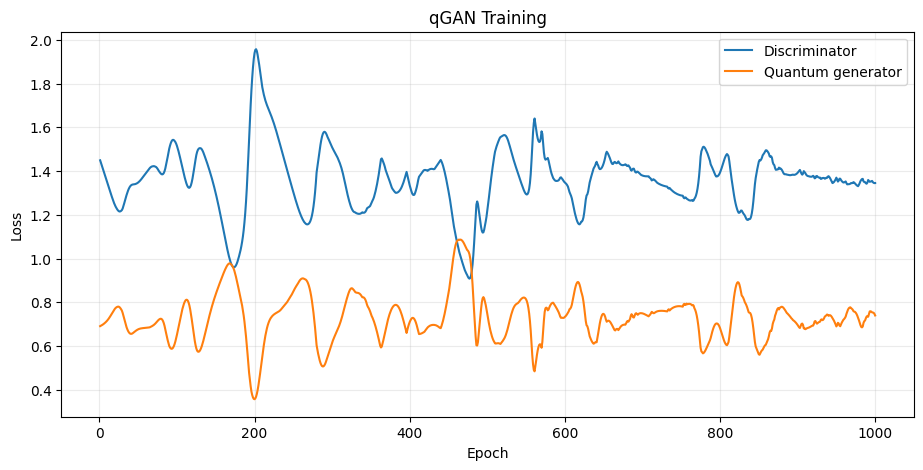

In [13]:
q_history_df = pd.DataFrame(q_history, columns=["epoch","D_loss","G_loss","grad_norm"])
print(q_history_df.tail())

plt.figure(figsize=(11,5))
plt.plot(q_history_df.epoch, q_history_df.D_loss, label="Discriminator")
plt.plot(q_history_df.epoch, q_history_df.G_loss, label="Quantum generator")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("qGAN Training")
plt.legend(); plt.grid(alpha=0.25); plt.show()

FINAL qGAN DISTRIBUTION
|000> | return center=-0.03241096 | probability=0.004127
|001> | return center=-0.02405206 | probability=0.001135
|010> | return center=-0.01569316 | probability=0.056301
|011> | return center=-0.00733426 | probability=0.218151
|100> | return center= 0.00102464 | probability=0.454499
|101> | return center= 0.00938354 | probability=0.231575
|110> | return center= 0.01774244 | probability=0.022871
|111> | return center= 0.02610134 | probability=0.011341
Probability sum: 1.0

 state  return_center     real  classical_GAN     qGAN
  000      -0.032411 0.016247       0.062002 0.004127
  001      -0.024052 0.020309       0.007387 0.001135
  010      -0.015693 0.073111       0.017256 0.056301
  011      -0.007334 0.198213       0.117913 0.218151
  100       0.001025 0.382616       0.396503 0.454499
  101       0.009384 0.215272       0.257286 0.231575
  110       0.017742 0.071487       0.131542 0.022871
  111       0.026101 0.022746       0.010111 0.011341


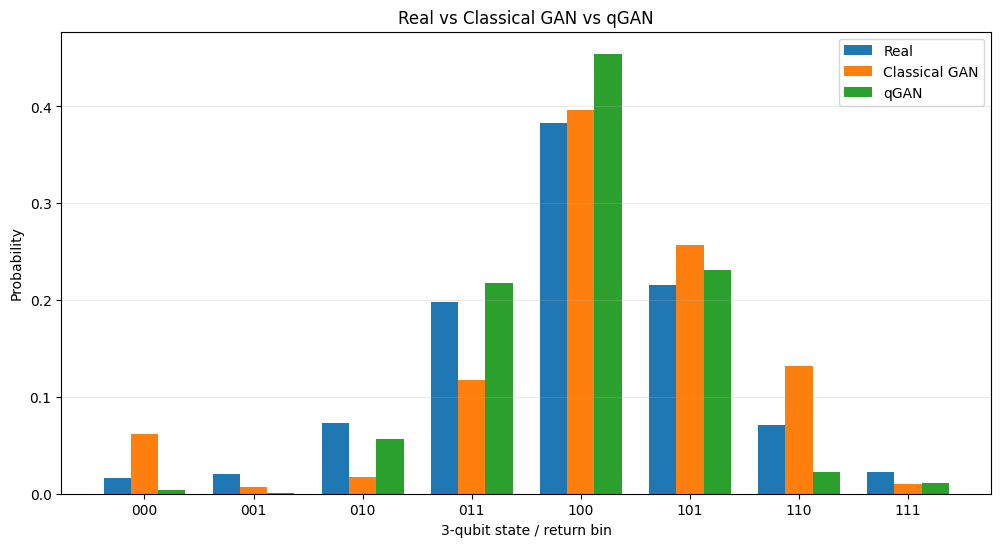

In [14]:
final_quantum_probs = quantum_probabilities(q_theta)

print("="*70)
print("FINAL qGAN DISTRIBUTION")
print("="*70)
for i,p in enumerate(final_quantum_probs):
    print(f"|{format(i,'03b')}> | return center={bin_centers[i]: .8f} | probability={p:.6f}")
print("Probability sum:", final_quantum_probs.sum())

comparison = pd.DataFrame({
    "state":[format(i,"03b") for i in range(NUM_BINS)],
    "return_center":bin_centers,
    "real":real_distribution,
    "classical_GAN":classical_probs,
    "qGAN":final_quantum_probs
})
print("\n", comparison.to_string(index=False))

x=np.arange(NUM_BINS); w=0.25
plt.figure(figsize=(12,6))
plt.bar(x-w, real_distribution, w, label="Real")
plt.bar(x, classical_probs, w, label="Classical GAN")
plt.bar(x+w, final_quantum_probs, w, label="qGAN")
plt.xticks(x,[format(i,"03b") for i in range(NUM_BINS)])
plt.xlabel("3-qubit state / return bin"); plt.ylabel("Probability")
plt.title("Real vs Classical GAN vs qGAN")
plt.legend(); plt.grid(axis="y",alpha=0.25); plt.show()

Number of synthetic days: 252
Initial price: 5881.6298828125
Final synthetic price: 6887.698762174423
Synthetic path return: 0.17105273528038412
First 20 sampled states: ['100', '010', '010', '101', '100', '011', '101', '011', '100', '100', '101', '101', '011', '011', '100', '000', '100', '101', '101', '100']
First 20 synthetic returns: [ 0.00102464 -0.01569316 -0.01569316  0.00938354  0.00102464 -0.00733426
  0.00938354 -0.00733426  0.00102464  0.00102464  0.00938354  0.00938354
 -0.00733426 -0.00733426  0.00102464 -0.03241096  0.00102464  0.00938354
  0.00938354  0.00102464]


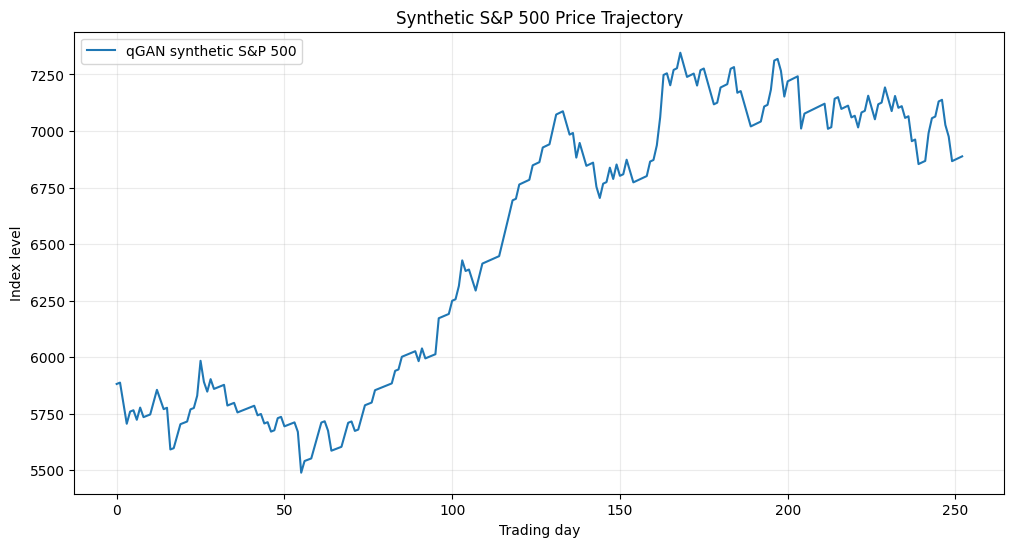

In [15]:
def sample_qgan_returns(probabilities, n_samples, rng):
    p = np.asarray(probabilities, dtype=float)
    p = np.maximum(p,0); p /= p.sum()
    bins = rng.choice(len(p), size=n_samples, p=p)
    return bin_centers[bins], bins

def generate_price_path(probabilities, n_days, initial_price, rng):
    r, bins = sample_qgan_returns(probabilities, n_days, rng)
    prices = initial_price*np.exp(np.cumsum(r))
    return r, bins, prices

N_DAYS = 252
initial_price = float(close.iloc[-1])
rng = np.random.default_rng(SEED+1)
synthetic_returns, sampled_bins, synthetic_prices = generate_price_path(
    final_quantum_probs, N_DAYS, initial_price, rng
)

print("Number of synthetic days:", N_DAYS)
print("Initial price:", initial_price)
print("Final synthetic price:", synthetic_prices[-1])
print("Synthetic path return:", synthetic_prices[-1]/initial_price-1)
print("First 20 sampled states:", [format(i,"03b") for i in sampled_bins[:20]])
print("First 20 synthetic returns:", synthetic_returns[:20])

plt.figure(figsize=(12,6))
plt.plot(np.insert(synthetic_prices,0,initial_price), label="qGAN synthetic S&P 500")
plt.xlabel("Trading day"); plt.ylabel("Index level")
plt.title("Synthetic S&P 500 Price Trajectory")
plt.legend(); plt.grid(alpha=0.25); plt.show()

Synthetic path array shape: (20, 252)


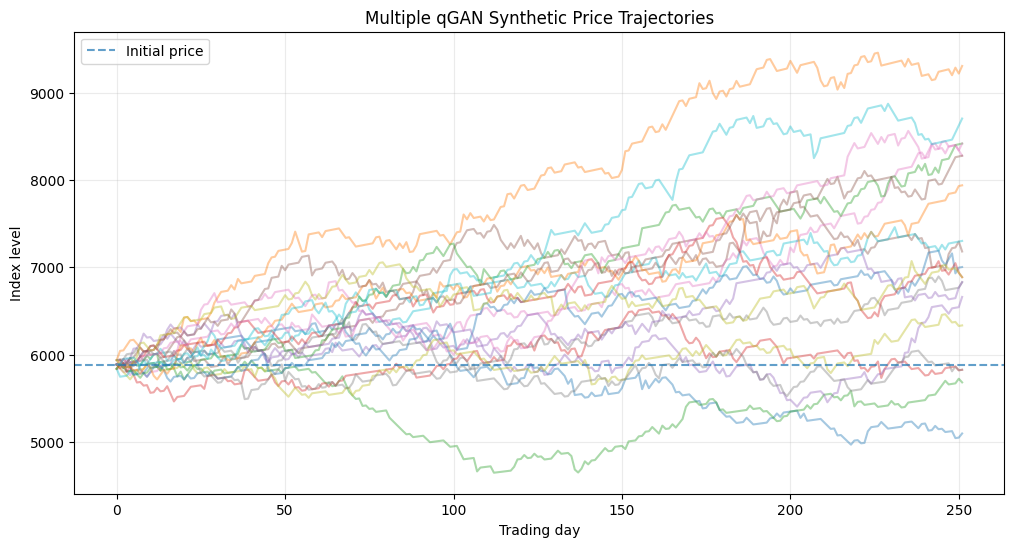

In [16]:
# Generate multiple trajectories
N_PATHS = 20
PATH_LENGTH = 252
rng = np.random.default_rng(SEED+10)
paths=[]
for _ in range(N_PATHS):
    _,_,p = generate_price_path(final_quantum_probs, PATH_LENGTH, initial_price, rng)
    paths.append(p)
paths=np.asarray(paths)

print("Synthetic path array shape:", paths.shape)

plt.figure(figsize=(12,6))
for p in paths:
    plt.plot(p, alpha=0.4)
plt.axhline(initial_price, linestyle="--", alpha=0.7, label="Initial price")
plt.xlabel("Trading day"); plt.ylabel("Index level")
plt.title("Multiple qGAN Synthetic Price Trajectories")
plt.legend(); plt.grid(alpha=0.25); plt.show()

In [20]:
try:
    from qiskit_aer import AerSimulator
    from qiskit_aer.noise import NoiseModel, depolarizing_error

    bound = generator_circuit.assign_parameters(dict(zip(generator_params,q_theta)), inplace=False)
    measured = bound.copy()
    measured.measure_all()
    SHOTS=4096

    aer=AerSimulator()
    result=aer.run(measured,shots=SHOTS,seed_simulator=SEED).result()
    counts=result.get_counts()
    shot_probs=np.zeros(NUM_BINS)
    for bitstring,count in counts.items():
        idx=int(bitstring.replace(" ",""),2)
        shot_probs[idx]=count/SHOTS

    print("="*70); print("IDEAL AER SHOT-BASED DISTRIBUTION"); print("="*70)
    print("Counts:",counts)
    print("Exact:",np.round(final_quantum_probs,5))
    print("Shots:",np.round(shot_probs,5))
    print("Sum:",shot_probs.sum())

    noise=NoiseModel()
    noise.add_all_qubit_quantum_error(depolarizing_error(0.002,1),["ry","rz"])
    noise.add_all_qubit_quantum_error(depolarizing_error(0.01,2),["cx"])
    noisy=AerSimulator(noise_model=noise)
    noisy_result=noisy.run(measured,shots=SHOTS,seed_simulator=SEED).result()
    noisy_counts=noisy_result.get_counts()
    noisy_probs=np.zeros(NUM_BINS)
    for bitstring,count in noisy_counts.items():
        idx=int(bitstring.replace(" ",""),2)
        noisy_probs[idx]=count/SHOTS

    print("\nNoisy probabilities:",np.round(noisy_probs,5))
    print("Noisy sum:",noisy_probs.sum())
except Exception as e:
    print("Aer section skipped:",repr(e))

IDEAL AER SHOT-BASED DISTRIBUTION
Counts: {'001': 3, '110': 78, '101': 958, '000': 17, '010': 204, '111': 53, '011': 891, '100': 1892}
Exact: [0.00413 0.00113 0.0563  0.21815 0.4545  0.23158 0.02287 0.01134]
Shots: [0.00415 0.00073 0.0498  0.21753 0.46191 0.23389 0.01904 0.01294]
Sum: 1.0

Noisy probabilities: [0.00806 0.00415 0.05811 0.2124  0.44849 0.22998 0.02393 0.01489]
Noisy sum: 1.0


In [21]:
def total_variation(p,q):
    p=np.asarray(p,float); q=np.asarray(q,float)
    p/=p.sum(); q/=q.sum()
    return .5*np.sum(np.abs(p-q))

def kl_div(p,q,eps=1e-12):
    p=np.asarray(p,float); q=np.asarray(q,float)
    p/=p.sum(); q/=q.sum()
    return np.sum(p*np.log((p+eps)/(q+eps)))

print("="*70)
print("FINAL DISTRIBUTION DISTANCES")
print("="*70)
print("Classical GAN TV:",total_variation(real_distribution,classical_probs))
print("qGAN TV:",total_variation(real_distribution,final_quantum_probs))
print("Classical GAN KL:",kl_div(real_distribution,classical_probs))
print("qGAN KL:",kl_div(real_distribution,final_quantum_probs))

summary=pd.DataFrame({
    "Metric":["Mean","Std","Skewness","Excess kurtosis","KS statistic","KS p-value","VaR 95%","CVaR 95%"],
    "Real":[np.mean(returns),np.std(returns),skew(returns),kurtosis(returns,fisher=True),np.nan,np.nan,real_var,real_cvar],
    "qGAN":[np.mean(synthetic_returns),np.std(synthetic_returns),skew(synthetic_returns),kurtosis(synthetic_returns,fisher=True),ks_stat,ks_p,q_var,q_cvar]
})
print("\nFINAL SUMMARY")
print(summary.to_string(index=False))

FINAL DISTRIBUTION DISTANCES
Classical GAN TV: 0.1617109685982593
qGAN TV: 0.10812426693585442
Classical GAN KL: 0.1301158654356633
qGAN KL: 0.09666209540063549

FINAL SUMMARY
         Metric      Real          qGAN
           Mean  0.000470  6.265997e-04
            Std  0.013494  8.448454e-03
       Skewness -0.820020 -5.273035e-01
Excess kurtosis 14.153271  2.294679e+00
   KS statistic       NaN  2.472440e-01
     KS p-value       NaN  9.129350e-12
        VaR 95% -0.018851 -1.569316e-02
       CVaR 95% -0.033079 -1.864336e-02
